In [1]:

import pandas as pd

df = pd.read_csv("HR-Analytics-Employee.csv")

print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df["Attrition"].value_counts())


Dataset Shape: (1470, 35)

Class Distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [2]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=[
    "Attrition", "EmployeeNumber",
    "EmployeeCount", "Over18", "StandardHours"
])

y = df["Attrition"].map({"Yes": 1, "No": 0})

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())


Training Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [3]:

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(
    sampling_strategy=1.0,
    random_state=42
)

X_train_over, y_train_over = ros.fit_resample(
    X_train, y_train
)

print("Before Oversampling:")
print(y_train.value_counts())

print("\nAfter Oversampling:")
print(y_train_over.value_counts())

print("\nNew Shape:", X_train_over.shape)


Before Oversampling:
Attrition
0    986
1    190
Name: count, dtype: int64

After Oversampling:
Attrition
0    986
1    986
Name: count, dtype: int64

New Shape: (1972, 30)


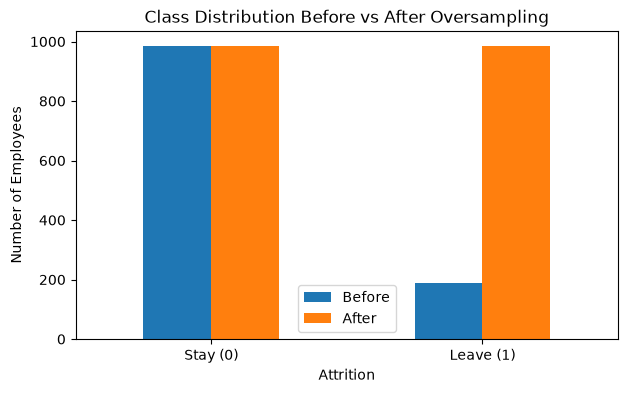

In [ ]:

import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Before": y_train.value_counts().sort_index(),
    "After": y_train_over.value_counts().sort_index()
})

comparison.index = ["Stay (0)", "Leave (1)"]

comparison.plot(kind="bar", figsize=(7, 4))

plt.title("Class Distribution Before vs After Oversampling")
plt.ylabel("Number of Employees")
plt.xlabel("Attrition")
plt.xticks(rotation=0)
plt.show()

# SMOTENCE


In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

ordinal_cols = [
    "Education", "EnvironmentSatisfaction",
    "JobInvolvement", "JobLevel",
    "JobSatisfaction", "PerformanceRating",
    "RelationshipSatisfaction", "WorkLifeBalance"
]

numeric_cols = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in ordinal_cols
]

categorical_cols = (
    X_train.select_dtypes(exclude="number").columns.tolist()
    + ordinal_cols
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


In [6]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

over_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

over_model.fit(X_train_over, y_train_over)

print("Model trained successfully!")


Model trained successfully!


In [7]:

from sklearn.metrics import classification_report, confusion_matrix

# Predict on original test data
y_pred_over = over_model.predict(X_test)

# Evaluation
print("Classification Report:")
print(classification_report(y_test, y_pred_over))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_over))


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.83      0.88       247
           1       0.45      0.70      0.55        47

    accuracy                           0.81       294
   macro avg       0.69      0.77      0.71       294
weighted avg       0.86      0.81      0.83       294


Confusion Matrix:
[[206  41]
 [ 14  33]]


In [8]:

ros_60 = RandomOverSampler(
    sampling_strategy=2/3,
    random_state=42
)

X_train_over60, y_train_over60 = ros_60.fit_resample(
    X_train, y_train
)

print("After Oversampling 60/40:")
print(y_train_over60.value_counts())
print("\nShape:", X_train_over60.shape)


After Oversampling 60/40:
Attrition
0    986
1    657
Name: count, dtype: int64

Shape: (1643, 30)


In [9]:

from sklearn.base import clone

# Create a fresh model with the same settings
over_model_60 = clone(over_model)

# Train on 60/40 oversampled data
over_model_60.fit(X_train_over60, y_train_over60)

print("Model trained successfully!")


Model trained successfully!


In [10]:

# Predict on original test data
y_pred_over60 = over_model_60.predict(X_test)

print("Classification Report - Oversampling 60/40:")
print(classification_report(y_test, y_pred_over60))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_over60))


Classification Report - Oversampling 60/40:
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       247
           1       0.48      0.64      0.55        47

    accuracy                           0.83       294
   macro avg       0.71      0.75      0.72       294
weighted avg       0.86      0.83      0.84       294


Confusion Matrix:
[[215  32]
 [ 17  30]]
